In [15]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_FILE = Path("../data/cleaned_job_placement_data.csv")
df = pd.read_csv(DATA_FILE)

print("Dataset shape:", df.shape)
display(df.head())
print(df["status"].value_counts(dropna=False))
print((df["status"].value_counts(normalize=True) * 100).round(2))

Dataset shape: (50000, 26)


,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,...,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status
0,27,Male,65.061656,83.842578,75.856526,Computer Science,58.221909,89.566305,64.474484,79.548913,...,5.805850,Tier 3,Not Matched,Medium,Not Required,15.0,No,18.0,Not Willing,Not Placed
1,24,Male,67.885626,64.973305,73.093588,Electronics,71.927978,54.591971,61.077306,73.316134,...,10.807739,Tier 1,Matched,High,Required,0.0,Unknown,0.0,Not Willing,Not Placed
2,33,Female,73.892471,68.834121,90.196460,Information Technology,72.445041,58.587088,79.494739,75.466980,...,5.476839,Tier 3,Not Matched,Low,Not Required,0.0,No,3.0,Not Willing,Placed
3,31,Male,74.145568,76.255126,75.586731,Mechanical,78.855676,61.022065,53.740386,73.676449,...,9.980580,Tier 2,Matched,Low,Not Required,0.0,Yes,6.0,Unknown,Not Placed
4,28,Male,60.475937,65.786336,80.801010,Information Technology,68.286776,65.713731,61.438314,88.994847,...,8.921233,Tier 2,Matched,Medium,Not Required,0.0,No,3.0,Willing,Not Placed


status
Not Placed    34870
Placed        15130
Name: count, dtype: int64
status
Not Placed    69.74
Placed        30.26
Name: proportion, dtype: float64


## Compare average interview-related scores by placement status

In [16]:
interview_summary = df.groupby("status")[
    ["technical_score", "aptitude_score", "communication_score"]
].mean().round(2)

print(interview_summary)

            technical_score  aptitude_score  communication_score
status                                                          
Not Placed            64.88           63.74                65.46
Placed                75.30           64.59                67.57


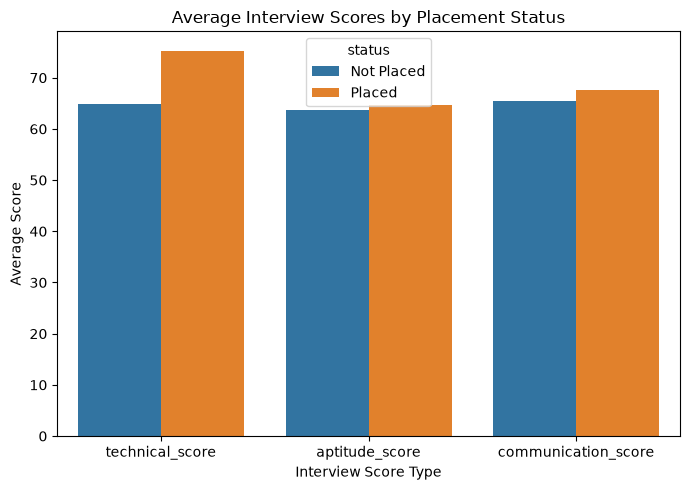

In [17]:
interview_summary = df.groupby("status")[
    ["technical_score", "aptitude_score", "communication_score"]
].mean().reset_index()

interview_long = interview_summary.melt(
    id_vars="status",
    var_name="Interview Score",
    value_name="Average Score"
)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=interview_long,
    x="Interview Score",
    y="Average Score",
    hue="status"
)

plt.title("Average Interview Scores by Placement Status")
plt.xlabel("Interview Score Type")
plt.ylabel("Average Score")
#plt.legend(title="Placement Status")
plt.tight_layout()
plt.show()


#### Key observations

- Technical score: Placed candidates have a much higher average technical score (75.30 vs 64.88). This is the strongest difference among these three scores.
- Aptitude score: The averages are very similar, with only a 0.85-point difference.
- Communication score: Placed candidates have a slightly higher average, by 2.11 points.

Preliminary insight: Technical scores show the clearest relationship with placement status in this summary. However, these averages alone don't prove that technical scores cause placement.

## Compare average skills match percentage by placement status

status
Not Placed    72.4
Placed        77.5
Name: skills_match_percentage, dtype: float64


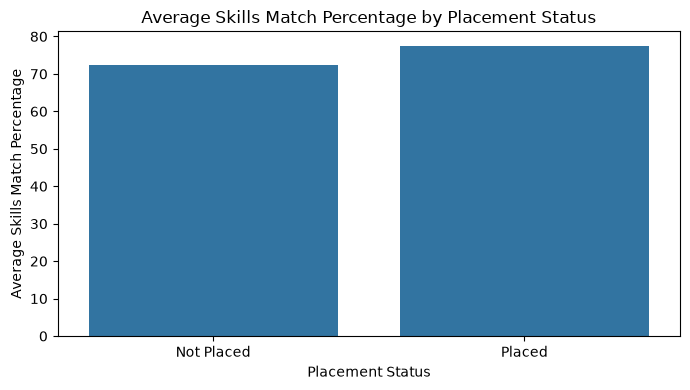

In [18]:
skills_summary = df.groupby("status")[
    "skills_match_percentage"
].mean().round(2)

print(skills_summary)

plt.figure(figsize=(7, 4))

sns.barplot(
    data=df,
    x="status",
    y="skills_match_percentage",
    errorbar=None
)

plt.title("Average Skills Match Percentage by Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Average Skills Match Percentage")
plt.tight_layout()
plt.show()

#### Key Observation

Placed candidates have an average skills match of 77.5%, compared with 72.4% for candidates who were not placed.

This suggests that a better match between a candidate's skills and job requirements is associated with a higher likelihood of placement. However, averages alone don't establish causation

## Calculate placement rate for each company tier

status        Not Placed  Placed
company_tier                    
Tier 1             70.06   29.94
Tier 2             69.58   30.42
Tier 3             69.46   30.54


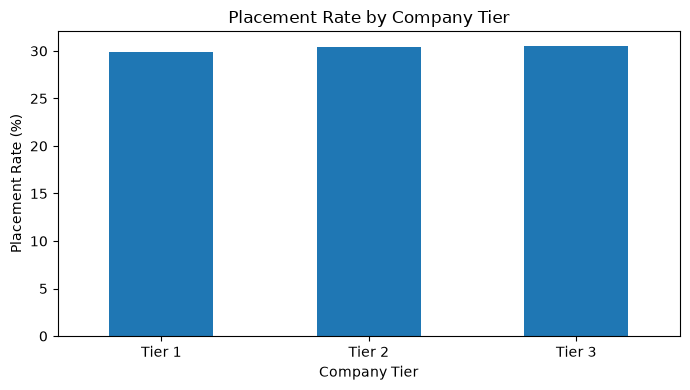

In [19]:
company_tier_summary = pd.crosstab(
    df["company_tier"],
    df["status"],
    normalize="index"
) * 100

print(company_tier_summary.round(2))

company_tier_summary["Placed"].plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Placement Rate by Company Tier")
plt.xlabel("Company Tier")
plt.ylabel("Placement Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Key observations
- Tier 3 has the highest placement rate at 30.54%.
- Tier 1 has the lowest placement rate at 29.94%.
- The difference between the highest and lowest placement rates is only 0.60 percentage points.

Insight: Placement rates are very similar across all three company tiers. In this dataset, company tier alone does not show a substantial difference in placement outcomes.

## Experience vs placement probability

                     total_candidates  placed_candidates  placement_rate
years_of_experience                                                     
0                               14952               2061           13.78
1                               13508               3259           24.13
2                                9966               3597           36.09
3                                6538               3204           49.01
4                                3548               2048           57.72
5                                1488                961           64.58


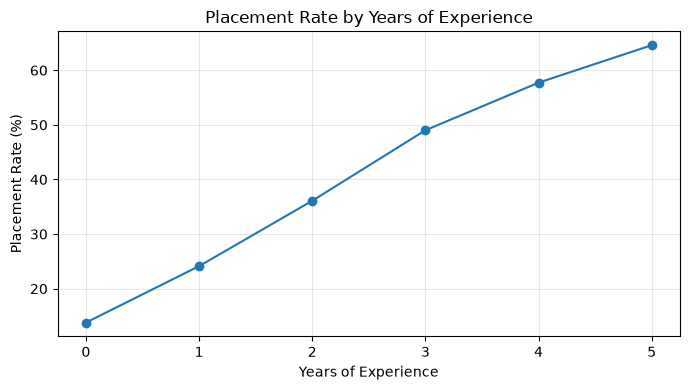

In [20]:
experience_summary = df.groupby("years_of_experience").agg(
    total_candidates=("status", "count"),
    placed_candidates=("status", lambda x: (x == "Placed").sum())
)

experience_summary["placement_rate"] = (
    experience_summary["placed_candidates"]
    / experience_summary["total_candidates"]
    * 100
)

print(experience_summary.round(2))


experience_summary["placement_rate"].plot(
    kind="line",
    marker="o",
    figsize=(7, 4)
)

plt.title("Placement Rate by Years of Experience")
plt.xlabel("Years of Experience")
plt.ylabel("Placement Rate (%)")
plt.xticks(range(6))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Key observations
- 0 years: Candidates with no experience have the lowest placement rate (13.78%).
- 3 years: The placement rate reaches 49.01%, nearly half of the candidates.
- 5 years: Candidates with five years of experience have the highest placement rate (64.58%).
- Overall trend: The observed placement rate increases consistently as years of experience increase.

Insight: In this dataset, more years of experience are associated with a higher placement rate. However, candidates with five years of experience are fewer in number than freshers, so we should consider the group sizes when interpreting the results.

## Competition level vs job acceptance

status             Not Placed  Placed
competition_level                    
High                    76.22   23.78
Low                     68.13   31.87
Medium                  68.10   31.90


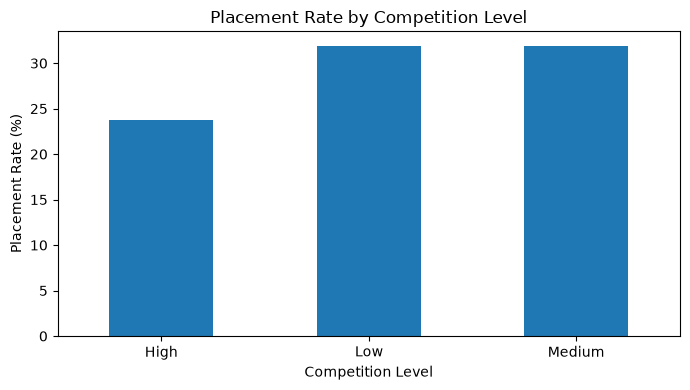

In [21]:
competition_summary = pd.crosstab(
    df["competition_level"],
    df["status"],
    normalize="index"
) * 100

print(competition_summary.round(2))

competition_summary["Placed"].sort_index().plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Placement Rate by Competition Level")
plt.xlabel("Competition Level")
plt.ylabel("Placement Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Key observations
- High competition: Has the lowest placement rate at 23.78%.
- Medium competition: Has the highest placement rate at 31.90%, just slightly above Low competition.
- Difference: The placement rate under High competition is about 8.1 percentage points lower than under Medium competition.

Insight: High competition is associated with a lower placement rate in this dataset. Low and Medium competition have very similar rates.

## Correlation analysis among numeric features

                         age_years  ssc_percentage  hsc_percentage  \
age_years                     1.00           -0.00           -0.00   
ssc_percentage               -0.00            1.00            0.00   
hsc_percentage               -0.00            0.00            1.00   
degree_percentage            -0.01            0.00            0.00   
technical_score              -0.01            0.01            0.01   
aptitude_score               -0.01            0.01            0.00   
communication_score          -0.00            0.00           -0.01   
skills_match_percentage       0.00           -0.01           -0.00   
certifications_count         -0.01           -0.01            0.00   
years_of_experience           0.00           -0.01           -0.00   
previous_ctc_lpa             -0.00           -0.00            0.01   
expected_ctc_lpa              0.00            0.00           -0.00   
notice_period_days           -0.00           -0.01            0.00   
employment_gap_month

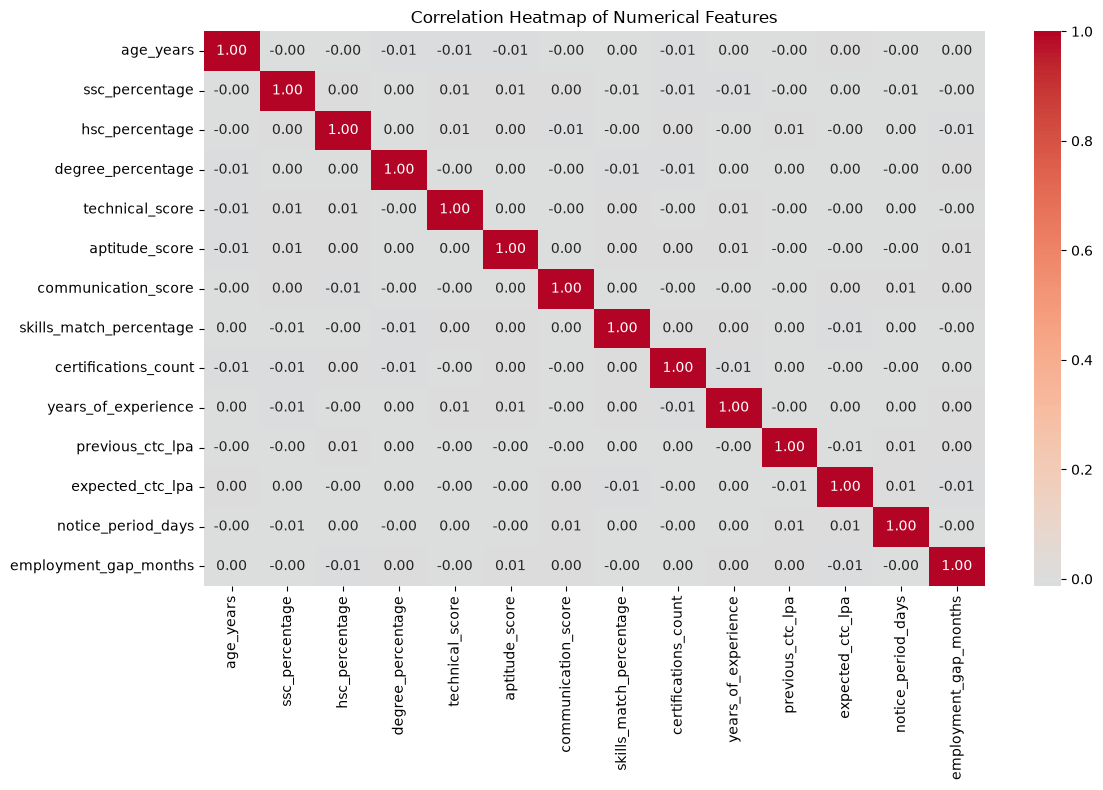

In [22]:
numeric_columns = df.select_dtypes(
    include="number"
).columns

correlation_matrix = df[numeric_columns].corr()

print(correlation_matrix.round(2))

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()